In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats

plt.style.use('ggplot')

In [ ]:
def CalculateGraphics(checkpoint,i,j):
  df = pd.read_csv('Model_'+ checkpoint +'_Scores_Results.csv', delimiter=";")
  df = df[['Mark', 'Score_50']].copy()
  df["Mark"] = df["Mark"].str.replace(',','.').astype(float)
  df["Score_50"] = df["Score_50"].str.replace(',','.').astype(float)

  corr_matrixp = df.corr(method='pearson')
  corr_matrixs = df.corr(method='spearman')
  corr_matrixk = df.corr(method='kendall')


  x = df["Mark"].to_numpy()
  y = df["Score_50"].to_numpy()

  slope, intercept, r, p, stderr = scipy.stats.linregress(x, y)
  line = f'Regression line: y={intercept:.2f}+{slope:.2f}x, r={r:.2f}'


  ax[irow,icol].plot(x, y, linewidth=0, marker='s', label='Data points')
  ax[irow,icol].plot(x, intercept + slope * x, label=line)
  ax[irow,icol].set_xlabel('Teacher''s grade')
  ax[irow,icol].set_ylabel('Semantic similarity')
  ax[irow,icol].legend(facecolor='white')
  ax[irow,icol].title.set_text( checkpoint + '\nPearson Correlation = ' + "{:.2f}".format(corr_matrixp.iat[0,1])
    + '\nSpearman Correlation = ' + "{:.2f}".format(corr_matrixs.iat[0,1])
    + '\nKendall Correlation = ' + "{:.2f}".format(corr_matrixk.iat[0,1])
    )

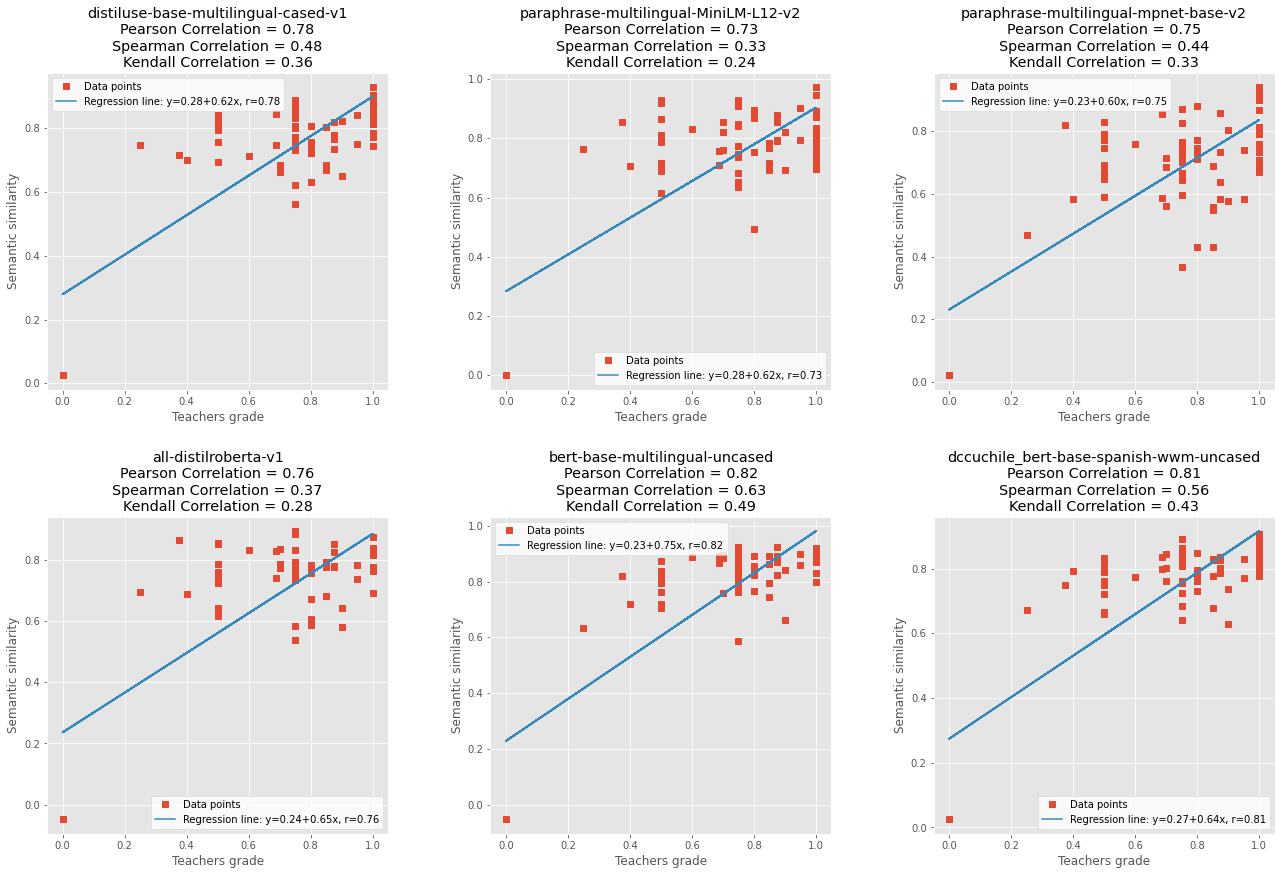

In [3]:
modelsToTest = [ 'distiluse-base-multilingual-cased-v1'
                ,'paraphrase-multilingual-MiniLM-L12-v2'
                ,'paraphrase-multilingual-mpnet-base-v2'
                ,'all-distilroberta-v1'
                ,'bert-base-multilingual-uncased'
                ,'dccuchile/bert-base-spanish-wwm-uncased'
              ]

fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(22, 14))

irow = 0
icol = 0

for checkpoint in modelsToTest:
  CalculateGraphics(checkpoint.replace('/','_'), irow, icol)
  icol = icol + 1
  if icol == 3:
    irow = 1
    icol = 0

fig.subplots_adjust(wspace=0.3,hspace=0.4)    
plt.show()